In [1]:
%pip install -U "qiskit[visualization]" qiskit-ibm-runtime


Note: you may need to restart the kernel to use updated packages.


Qiskit Fall Fest 2026

Challenge 2: Make the Quantum Coin Biased

Objective

To create single-qubit quantum circuits with unequal probabilities of measuring 0 and 1.

Two circuits will be tested. Circuit A is designed to favor 0, while Circuit B is designed to favor 1. Each circuit will be executed for 100 shots on IBM Quantum hardware.

In [2]:
from getpass import getpass
from qiskit_ibm_runtime import QiskitRuntimeService

api_key = getpass("Enter your IBM Quantum API key: ")
crn = input("Enter your IBM Quantum CRN: ").strip()

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=api_key,
    instance=crn
)

print("Successfully connected to IBM Quantum.")

Enter your IBM Quantum API key:  ········
Enter your IBM Quantum CRN:  crn:v1:bluemix:public:quantum-computing:us-east:a/4db3032ff9574ab8b189d65aca927eb7:afda762a-3892-48ce-beff-b56cb09b4f57::


qiskit_runtime_service._discover_account:WARNING:2026-10-11 22:27:44,116: Loading account with the given token. A saved account will not be used.


Successfully connected to IBM Quantum.


In [3]:
backend = service.least_busy(
    min_num_qubits=1,
    operational=True,
    simulator=False
)

print("Selected quantum computer:", backend.name)
print("Backend status:", backend.status().status_msg)

Selected quantum computer: ibm_fez
Backend status: active


Circuit A: Expected 75% zeros and 25% ones


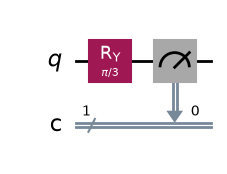

In [4]:
from qiskit import QuantumCircuit
from math import pi
from IPython.display import display

# Circuit A: 0 is expected to be more frequent
circuit_a = QuantumCircuit(1, 1)
circuit_a.ry(pi / 3, 0)
circuit_a.measure(0, 0)

# Circuit B: 1 is expected to be more frequent
circuit_b = QuantumCircuit(1, 1)
circuit_b.ry(2 * pi / 3, 0)
circuit_b.measure(0, 0)

circuits = [circuit_a, circuit_b]

print("Circuit A: Expected 75% zeros and 25% ones")
display(circuit_a.draw("mpl"))


Predictions Before Execution

Circuit A

The (R_y(\pi/3)) gate is expected to produce approximately 75% zeros and 25% ones. Therefore, 0 should occur more frequently.

Circuit B

The (R_y(2\pi/3)) gate is expected to produce approximately 25% zeros and 75% ones. Therefore, 1 should occur more frequently.

Each circuit will be executed for 100 shots. The actual counts may differ from the predicted probabilities.

In [5]:
from qiskit.transpiler import generate_preset_pass_manager

pass_manager = generate_preset_pass_manager(
    backend=backend,
    optimization_level=1
)

compiled_circuits = pass_manager.run(circuits)

print("Both circuits are ready for hardware execution.")

Both circuits are ready for hardware execution.


In [7]:
from qiskit_ibm_runtime import SamplerV2

sampler = SamplerV2(mode=backend)

job = sampler.run(
    compiled_circuits,
    shots=100
)

print("Job ID:", job.job_id())
print("Waiting for results...")

result = job.result()

print("Hardware execution completed.")

C:\Users\SUSEELA\AppData\Local\Temp\ipykernel_18156\644712009.py:3: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


Job ID: db5s54clf4us73c4fq2g
Waiting for results...
Hardware execution completed.


In [8]:
print("Available result fields:", result[0].data.keys())

counts_a = result[0].data.c.get_counts()
counts_b = result[1].data.c.get_counts()

print("Circuit A counts:", counts_a)
print("Circuit A total shots:", sum(counts_a.values()))

print()

print("Circuit B counts:", counts_b)
print("Circuit B total shots:", sum(counts_b.values()))

Available result fields: dict_keys(['c'])
Circuit A counts: {'1': 28, '0': 72}
Circuit A total shots: 100

Circuit B counts: {'0': 28, '1': 72}
Circuit B total shots: 100


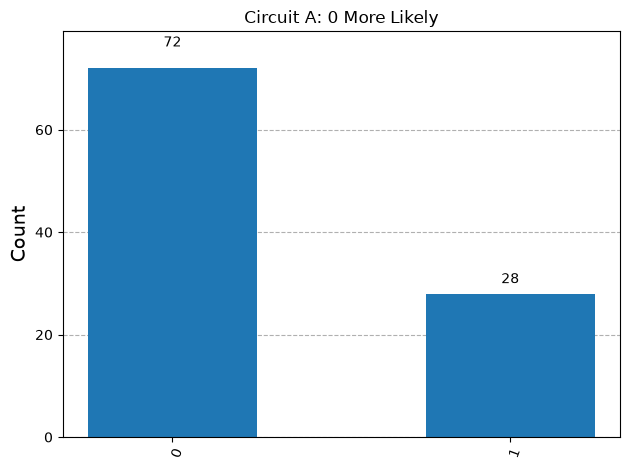

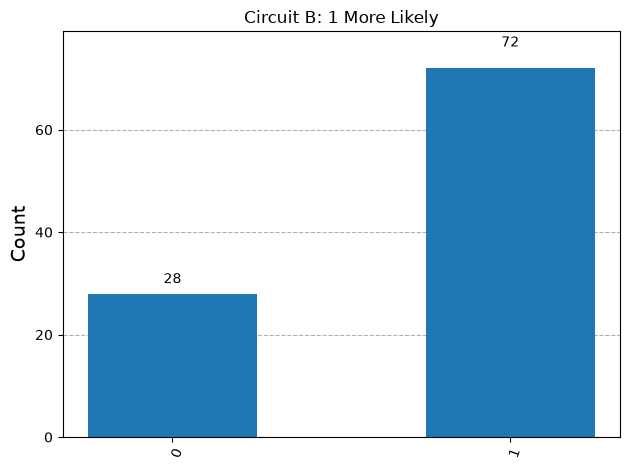

In [9]:
from qiskit.visualization import plot_histogram

display(plot_histogram(
    counts_a,
    title="Circuit A: 0 More Likely"
))

display(plot_histogram(
    counts_b,
    title="Circuit B: 1 More Likely"
))

In [10]:
import pandas as pd

comparison = pd.DataFrame([
    {
        "Circuit": "A",
        "Gate": "Ry(pi/3)",
        "Predicted 0 (%)": 75,
        "Predicted 1 (%)": 25,
        "Actual Counts": str(counts_a),
        "Total Shots": sum(counts_a.values())
    },
    {
        "Circuit": "B",
        "Gate": "Ry(2pi/3)",
        "Predicted 0 (%)": 25,
        "Predicted 1 (%)": 75,
        "Actual Counts": str(counts_b),
        "Total Shots": sum(counts_b.values())
    }
])

display(comparison)

,Circuit,Gate,Predicted 0 (%),Predicted 1 (%),Actual Counts,Total Shots
0,A,Ry(pi/3),75,25,"{'1': 28, '0': 72}",100
1,B,Ry(2pi/3),25,75,"{'0': 28, '1': 72}",100


Observation and Conclusion

Circuit A was designed to make outcome 0 more likely. Circuit B was designed to make outcome 1 more likely.

The measured counts were compared with the predicted probabilities. Small differences may occur because the experiments were performed on real quantum hardware.

The experiment demonstrates that changing the rotation angle of a quantum gate changes the probability of obtaining 0 or 1 when the qubit is measured.

Challenge Question

How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?

Quantum gates change the state of a qubit. A rotation gate such as (R_y) changes the qubit's state according to its rotation angle. This changes the probabilities of measuring 0 and 1. By choosing a suitable angle, we can make either outcome more likely.